<a href="https://colab.research.google.com/github/emilygimenes/final-project/blob/main/final_proj_visual.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Missing values before cleaning: taxonomy           0
concept            0
label              6
description        6
unit               0
value              0
accn               0
form               0
filed              0
fy               569
fp               569
start           9368
end                0
frame          15333
dtype: int64
Top 5 concepts:                                              concept  count          mean  \
283                                    NetIncomeLoss    338  2.480933e+10   
201                                      GrossProfit    338  4.305201e+10   
443                               StockholdersEquity    264  8.310052e+10   
470    WeightedAverageNumberOfSharesOutstandingBasic    234  7.605903e+09   
469  WeightedAverageNumberOfDilutedSharesOutstanding    234  7.658115e+09   

           median  
283  1.391750e+10  
201  2.431300e+10  
443  7.410000e+10  
470  5.488138e+09  
469  5.518106e+09  
Descriptive Statistics:           count          mean         

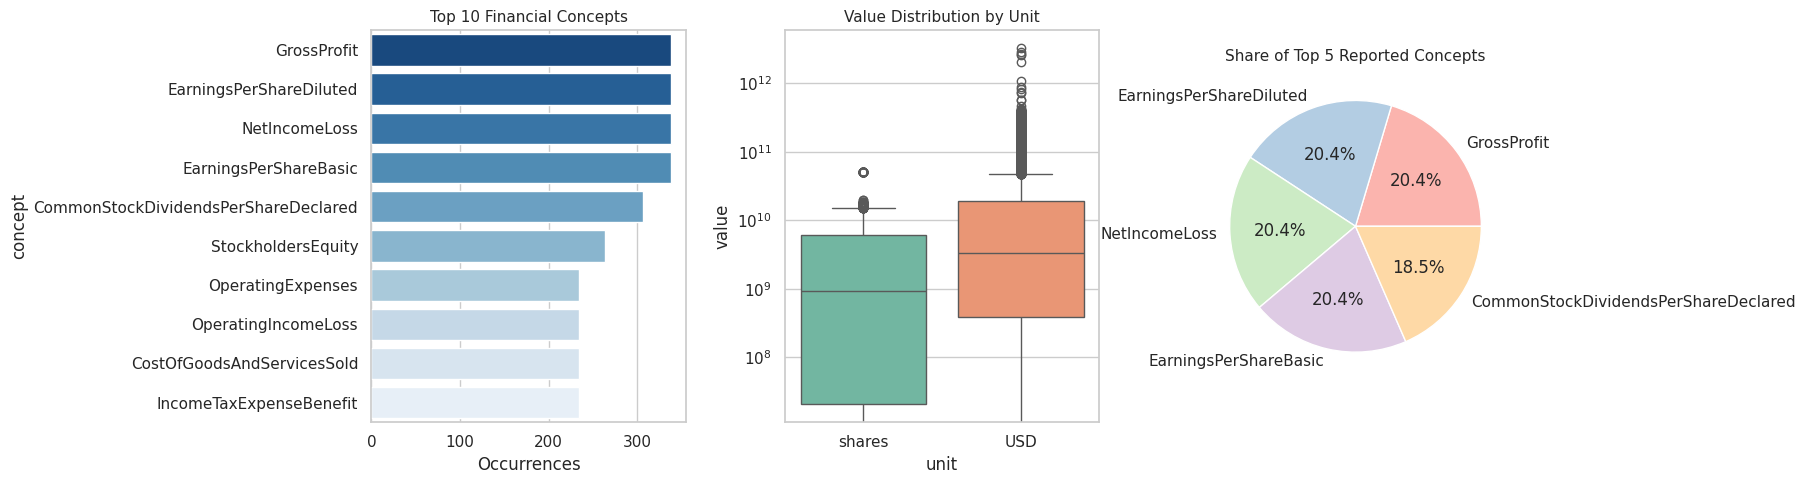

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('/content/financial_facts.csv')

# Data Cleaning/filtering
df_clean = df.drop_duplicates().copy()
df_filtered = df_clean[df_clean['unit'].isin(['USD', 'shares'])].copy()

#missing values
print("Missing values before cleaning:", df.isnull().sum())

#Data Manipulation
concept_summary = df_filtered.groupby('concept')['value'].agg(['count', 'mean', 'median']).reset_index()
concept_summary_sorted = concept_summary.sort_values(by='count', ascending=False)
print("Top 5 concepts:", concept_summary_sorted.head())

# Statistical Analysis
desc_stats = df_filtered.groupby('unit')['value'].describe()
print("Descriptive Statistics:", desc_stats)
numeric_df = df_filtered.select_dtypes(include=['number'])
print("Correlation:", numeric_df.corr())

# Visualizations & Saving File
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Visualization 1: bar chart
top_concepts = df_clean['concept'].value_counts().head(10)
sns.barplot(
    x=top_concepts.values,
    y=top_concepts.index,
    hue=top_concepts.index,
    legend=False,
    ax=axes[0],
    palette="Blues_r"
)
axes[0].set_title("Top 10 Financial Concepts", fontsize=11)
axes[0].set_xlabel("Occurrences")

# Visualization 2: Box Plot
sns.boxplot(
    data=df_filtered,
    x='unit',
    y='value',
    hue='unit',
    legend=False,
    ax=axes[1],
    palette="Set2"
)
axes[1].set_yscale('log')
axes[1].set_title("Value Distribution by Unit", fontsize=11)

# Visualization 3: Pie Chart
top_5_concepts = df_clean['concept'].value_counts().head(5)
axes[2].pie(
    top_5_concepts.values,
    labels=top_5_concepts.index,
    autopct='%1.1f%%',
    colors=sns.color_palette("Pastel1")
)
axes[2].set_title("Share of Top 5 Reported Concepts", fontsize=11)

plt.tight_layout()

# Save image file
plt.savefig('visualizations.png', dpi=300)
plt.show()